# 06 · GrabGo: Shelf Camera, Customer Photo, or Both? Image-Based Checkout Decided by the Owner's Trade-offs

**Juan Antonio Sainz Gálvez** · Applied AI & ML, Conestoga College · [Portfolio home](../README.md)

<a href="https://colab.research.google.com/github/antoniosg2025-stack/applied-ai-research-portfolio/blob/main/notebooks/06_grabgo_images_owner_tradeoffs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Main thesis question.** How can LLM agents learn, from an owner's approvals, rejections and corrections, a **decision profile** grounded in the owner's personality and situation (constraints and strengths: economic, skills, cognitive, family and business), so that they **minimize the gap between the agent's decision and the decision the owner would have made**, across different types of decisions, as the owner evolves, and when other users operate the system on the owner's behalf, **deferring to the owner** whenever that gap is likely to be large?
>
> **Error, in this portfolio, always means:** the agent decided differently from how the owner would have decided.

**This case:** *GrabGo* turns a shelf or fridge into a store: the customer takes products, sends a photo by WhatsApp, and pays by phone. A shelf camera can confirm what was taken. I will start GrabGo next to my vending machines, with different products. Some locations (the car dealership) may not want a camera inside, so I may trust the customer's photo alone. The point is not perfect vision: it is the cheapest operation that I would accept, location by location, and a system that learns by itself from corrections.


In [1]:
# Visual style used across the portfolio
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import FancyBboxPatch

PALETTE = {"navy": "#1B2A41", "teal": "#0F7C80", "gold": "#E0A526",
           "coral": "#D9534F", "sky": "#5BA4CF", "grey": "#8A94A6", "light": "#F4F6F9"}
POLICY_COLORS = [PALETTE["grey"], PALETTE["sky"], PALETTE["gold"], PALETTE["teal"], PALETTE["coral"]]

mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#D5DAE1", "axes.grid": True, "grid.color": "#E9ECF1", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "axes.labelcolor": "#3A4556", "xtick.color": "#5A6576", "ytick.color": "#5A6576",
    "legend.frameon": False, "font.family": "DejaVu Sans",
    "axes.prop_cycle": mpl.cycler(color=POLICY_COLORS),
})


def box(ax, xy, w, h, text, color, fontsize=10, text_color="white"):
    """Rounded box for infographics."""
    ax.add_patch(FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=color, ec="none"))
    if text:
        ax.text(xy[0] + w / 2, xy[1] + h / 2, text, ha="center", va="center",
                color=text_color, fontsize=fontsize, fontweight="bold")


def arrow(ax, start, end, color="#8A94A6"):
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2, shrinkA=4, shrinkB=4))


def thesis_card(case, profile, decision, signal):
    """The same infographic opens every notebook: owner profile -> agent decision model -> act or ask."""
    fig, ax = plt.subplots(figsize=(12, 4.6)); ax.set_xlim(0, 12); ax.set_ylim(0, 4.6); ax.axis("off")
    box(ax, (0.1, 0.35), 4.0, 3.5, "", PALETTE["navy"])
    ax.text(2.1, 3.45, "OWNER PROFILE", ha="center", color="white", fontsize=11, fontweight="bold")
    for i, item in enumerate(profile[:5]):
        ax.text(0.3, 2.9 - i * 0.5, "• " + item, color="white", fontsize=9, va="center")
    box(ax, (4.55, 1.55), 3.2, 1.6, "Agent learns how\nthe owner decides:\n" + decision, PALETTE["teal"], fontsize=10.5)
    box(ax, (4.55, 0.35), 3.2, 0.9, "learns from:\n" + signal, PALETTE["sky"], fontsize=9.5)
    box(ax, (8.3, 2.5), 3.5, 1.1, "Likely the same decision\nas the owner  ->  ACT", PALETTE["gold"], fontsize=10.5)
    box(ax, (8.3, 0.75), 3.5, 1.1, "Likely a different decision\n->  ASK THE OWNER", PALETTE["coral"], fontsize=10.5)
    arrow(ax, (4.1, 2.35), (4.5, 2.35)); arrow(ax, (7.8, 2.6), (8.25, 3.0)); arrow(ax, (7.8, 2.1), (8.25, 1.3))
    ax.set_title("Case: " + case, pad=4)
    plt.show()


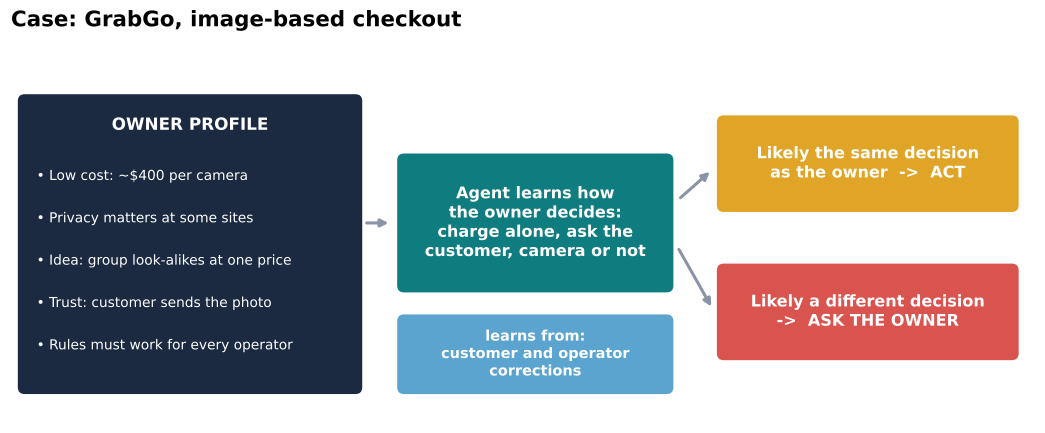

In [2]:
thesis_card("GrabGo, image-based checkout",
            ["Low cost: ~$400 per camera", "Privacy matters at some sites",
             "Idea: group look-alikes at one price", "Trust: customer sends the photo",
             "Rules must work for every operator"],
            "charge alone, ask the\ncustomer, camera or not",
            "customer and operator\ncorrections")

## 1. Literature

| Research line | Key result | What it gives this case |
|---|---|---|
| Automatic checkout datasets [1, 2] | Retail checkout recognition is large-scale, fine-grained and few-shot; benchmarks moved to synthetic training and video | Look-alike products are the hard case |
| Embedding-based retail recognition [3, 4] | Metric-learned CLIP embeddings classify new products by nearest neighbour without retraining; zero-shot VLMs struggle with fine-grained SKUs | New products enter by adding a few reference photos |
| Multi-view learning [5] | Combining views of the same object with complementary information improves recognition | The shelf camera and the phone photo are two views of one cart |
| Active learning with a noisy oracle [6] | Human corrections contain errors; reviewing suspected errors beats trusting every label | Customer corrections must be weighted, not blindly trusted |
| The cost of "automatic" stores [7] | Reports in 2024 said about 700 of every 1,000 Just Walk Out transactions in 2022 needed human review, against a target of 50; Amazon disputed the figures | Human review per 1,000 carts is the number that decides viability |

**Gap.** Vision research minimizes recognition error. A small operator needs to minimize **money charged wrong, questions to customers, hardware, and privacy cost**, with weights that are his, and that differ by location.


## 2. Experiment 1: which view, and does the price layout matter?

40 products, including 8 look-alike pairs (same brand, different flavour). Each product is an embedding cluster; the recognizer compares each item's image with reference photos (prototypes). Three image setups:

- **Shelf camera only**: sees every item taken; image quality fixed.
- **Customer photo only**: sharper per item, but the customer sometimes leaves an item out of the photo (3%).
- **Both**: the two views are combined.

Two price layouts:

- **Random prices**: look-alikes may have different prices.
- **Price-tiered layout**: each look-alike pair shares a price and a shelf (the owner's idea), so confusing them costs nothing.

The system asks the customer to confirm only when it is unsure, and every confirmed correction is added to the reference photos (with 90% reliable customers).


In [3]:
import numpy as np
import pandas as pd

D, K, PAIRS = 64, 40, 8
PRICES = np.array([1.5, 2.0, 2.5, 3.0])

def catalog(seed):
    rng = np.random.default_rng(seed)
    m = rng.normal(size=(K, D))
    for i in range(PAIRS): m[2 * i + 1] = m[2 * i] + 0.5 * rng.normal(size=D)
    return m / np.linalg.norm(m, axis=1, keepdims=True), rng

def view(rng, mu, noise):
    v = mu + noise * rng.normal(size=D) / np.sqrt(D) * 4
    return v / np.linalg.norm(v)

def run(setup, tiered, carts=3000, tau=0.05, seed=0):
    means, rng = catalog(seed)
    price = rng.choice(PRICES, K)
    if tiered:
        for i in range(PAIRS): price[2 * i + 1] = price[2 * i]
    sums = np.array([sum(view(rng, means[k], 0.32) for _ in range(5)) for k in range(K)])
    wrong_dollars = asks = missed = 0.0
    for _ in range(carts):
        items = rng.integers(0, K, rng.integers(1, 5))
        preds, margins = [], []
        for k in items:
            if setup == "customer photo only" and rng.random() < 0.03:
                missed += price[k]; continue                       # left out of the photo: not charged
            if setup == "shelf camera only": v = view(rng, means[k], 0.36)
            elif setup == "customer photo only": v = view(rng, means[k], 0.28)
            else: v = view(rng, means[k], 0.36) + view(rng, means[k], 0.28); v /= np.linalg.norm(v)
            protos = sums / np.linalg.norm(sums, axis=1, keepdims=True); s = protos @ v
            top = np.argsort(s)[-2:]; preds.append((k, top[1], v)); margins.append(s[top[1]] - s[top[0]])
        if not preds: continue
        ask = min(margins) < tau
        if ask:
            asks += 1
            for k, p, v in preds:
                fixed = p == k or rng.random() < 0.9
                label = k if fixed else p
                sums[label] += v                                    # the system learns from the confirmation
                if not fixed: wrong_dollars += abs(price[p] - price[k])
        else:
            for k, p, v in preds: wrong_dollars += abs(price[p] - price[k])
    n = carts / 1000
    return dict(setup=setup, layout="price-tiered" if tiered else "random prices",
                wrong_charges_dollars_per_1000_carts=wrong_dollars / n, items_never_charged_dollars_per_1000_carts=missed / n,
                customer_questions_per_1000_carts=asks / n)

SETUPS = ["shelf camera only", "customer photo only", "camera + photo"]
res = pd.DataFrame([run(s, t, seed=sd) for s in SETUPS for t in (False, True) for sd in range(3)])
res = res.groupby(["setup", "layout"]).mean().round(1).reindex(SETUPS, level=0)
res

wrong_charges_dollars_per_1000_carts  \
setup               layout                                                
shelf camera only   price-tiered                                    1.9   
                    random prices                                  19.1   
customer photo only price-tiered                                    0.2   
                    random prices                                   7.5   
camera + photo      price-tiered                                    0.0   
                    random prices                                   3.7   

                                   items_never_charged_dollars_per_1000_carts  \
setup               layout                                                      
shelf camera only   price-tiered                                          0.0   
                    random prices                                         0.0   
customer photo only price-tiered                                        160.1   
                    random prices                                       158.6   
camera + photo      price-tiered                                          0.0   
                    random prices                                         0.0   

                                   customer_questions_per_1000_carts  
setup               layout                                            
shelf camera only   price-tiered                               407.7  
                    random prices                              407.7  
customer photo only price-tiered                               363.1  
                    random prices                              363.1  
camera + photo      price-tiered                               318.7  
                    random prices                              318.7

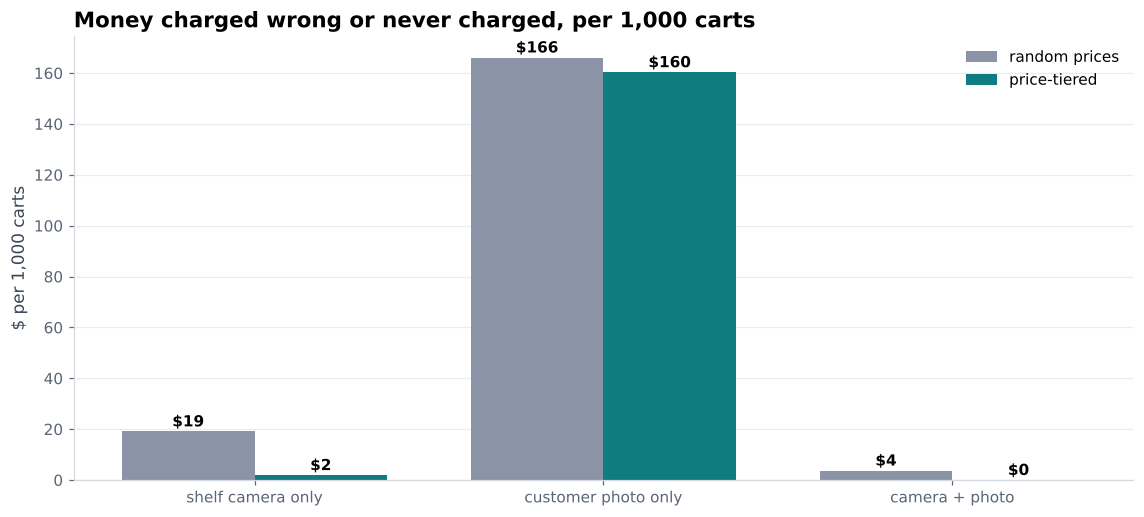

In [4]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
x = np.arange(len(SETUPS)); w = 0.38
for j, (lay, c) in enumerate([("random prices", PALETTE["grey"]), ("price-tiered", PALETTE["teal"])]):
    vals = [res.loc[(s, lay), "wrong_charges_dollars_per_1000_carts"] + res.loc[(s, lay), "items_never_charged_dollars_per_1000_carts"] for s in SETUPS]
    bars = ax.bar(x + (j - 0.5) * w, vals, w, color=c, label=lay)
    for b, v in zip(bars, vals): ax.text(b.get_x() + b.get_width() / 2, v + 2, f"${v:.0f}", ha="center", fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(SETUPS); ax.grid(axis="x", visible=False)
ax.set_title("Money charged wrong or never charged, per 1,000 carts")
ax.set_ylabel("$ per 1,000 carts"); ax.legend()
plt.tight_layout(); plt.show()

## 3. Experiment 2: the same results, three different owner decisions

The table above does not choose a setup; the owner's profile does. Each location gets the owner's weights: the cost of a camera (two cameras at about \$400 each, spread over two years), what a customer question costs him in friction, and a **privacy cost** if a camera is inside. The privacy weights are mine: high at the dealership (I expect them to object to a camera), low in a 200-person factory break room with trusted staff. The agent picks, for each location, the setup with the lowest total cost **under that location's weights**.


In [5]:
CARTS_PER_MONTH = {"car dealership": 600, "hotel (next to the vending machine)": 400, "200-person factory": 1500}
PRIVACY = {"car dealership": 300.0, "hotel (next to the vending machine)": 60.0, "200-person factory": 10.0}   # $ per month, owner's weights
CAMERA_MONTHLY = 2 * 400 / 24
FRICTION_PER_QUESTION = 0.25

rows = []
for loc, carts in CARTS_PER_MONTH.items():
    for s in SETUPS:
        r = res.loc[(s, "price-tiered")]
        money = (r.wrong_charges_dollars_per_1000_carts + r.items_never_charged_dollars_per_1000_carts) * carts / 1000
        questions = r.customer_questions_per_1000_carts * carts / 1000 * FRICTION_PER_QUESTION
        hw = 0 if s == "customer photo only" else CAMERA_MONTHLY
        priv = 0 if s == "customer photo only" else PRIVACY[loc]
        rows.append(dict(location=loc, setup=s, money_errors=money, question_friction=questions, cameras=hw, privacy=priv,
                         total_monthly_cost=money + questions + hw + priv))
choice = pd.DataFrame(rows).round(1)
best = choice.loc[choice.groupby("location").total_monthly_cost.idxmin(), ["location", "setup", "total_monthly_cost"]]
print("Setup the agent chooses for each location, given the owner's weights:"); print(best.to_string(index=False))
choice.pivot(index="location", columns="setup", values="total_monthly_cost")

Setup the agent chooses for each location, given the owner's weights:
                           location               setup  total_monthly_cost
                 200-person factory      camera + photo               162.8
                     car dealership customer photo only               150.6
hotel (next to the vending machine) customer photo only               100.4


setup,camera + photo,customer photo only,shelf camera only
location,,,
200-person factory,162.8,376.6,199.1
car dealership,381.1,150.6,395.6
hotel (next to the vending machine),125.2,100.4,134.9


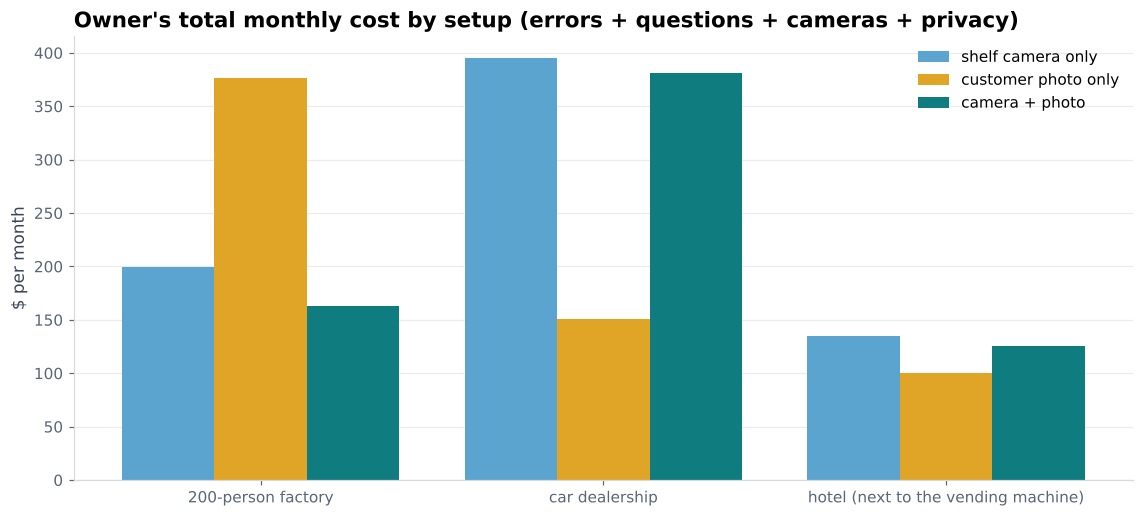

In [6]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
piv = choice.pivot(index="location", columns="setup", values="total_monthly_cost")[SETUPS]
x = np.arange(len(piv)); w = 0.27
for j, (s, c) in enumerate(zip(SETUPS, [PALETTE["sky"], PALETTE["gold"], PALETTE["teal"]])):
    ax.bar(x + (j - 1) * w, piv[s], w, color=c, label=s)
ax.set_xticks(x); ax.set_xticklabels(piv.index); ax.grid(axis="x", visible=False)
ax.set_title("Owner's total monthly cost by setup (errors + questions + cameras + privacy)")
ax.set_ylabel("$ per month"); ax.legend()
plt.tight_layout(); plt.show()

## 4. Findings

> **Key finding 1.** The owner's price idea is a strong, free lever: grouping each look-alike pair at **one price** cuts the money charged wrong by recognition errors by about 90% in every setup (shelf camera: from about \$19 to \$2 per 1,000 carts; both views: from about \$4 to \$0), **without adding hardware**. The confusions remain, but they no longer cost anything.
>
> **Key finding 2.** With the customer photo alone, recognition is not the problem: the real cost is items **left out of the photo** (about \$160 per 1,000 carts, 16 cents a cart, at an assumed 3% omission rate). Trusting the customer is a decision about honesty and habit, not about vision accuracy.
>
> **Key finding 3.** The same measured performance leads to **different decisions by location** once the owner's weights are applied: no camera at the dealership or the hotel, where privacy and camera cost outweigh the omissions, but camera plus photo in a busy factory, where omissions add up and privacy weighs little. The right setup is not a property of the vision system; it is a property of the owner's profile for that place. An agent that knows those weights can configure a new location the way the owner would, and ask when a location resembles none he has decided before.

**Limitations.** Simulated embeddings, an assumed 3% omission rate for customer photos, and owner weights stated by me rather than learned from my decisions (the thesis would learn them from approvals of past setups). The system learns recognition alone from confirmations; it does not yet learn the weights.

## 5. Thesis questions

1. Can the agent learn the owner's privacy and cost weights from his choices at past locations, and propose the setup for a new one?
2. When an operator (a specifier) configures a location, how does the agent keep the owner's weights and pass the operator's preferences to the owner (notebook 01)?
3. How should customer corrections be trusted when the customer is also the one paying?

## References

1. Wei, X.-S., Cui, Q., Yang, L., Wang, P., & Liu, L. (2019). *RPC: A Large-Scale Retail Product Checkout Dataset.* arXiv:1901.07249.
2. Naphade, M., et al. (2023). *The 7th AI City Challenge.* CVPR Workshops. arXiv:2304.07500.
3. *RetailKLIP: Finetuning OpenCLIP backbone using metric learning on a single GPU for zero-shot retail product image classification* (2023). arXiv:2312.10282.
4. Tur, A. O., Conti, A., et al. (2024). *Exploring Fine-grained Retail Product Discrimination with Zero-shot Object Classification Using Vision-Language Models.* arXiv:2409.14963.
5. Xu, C., Tao, D., & Xu, C. (2013). *A Survey on Multi-view Learning.* arXiv:1304.5634.
6. Schubert, M., Riedlinger, T., Kahl, K., & Rottmann, M. (2024). *Deep Active Learning with Noisy Oracle in Object Detection.* VISAPP 2024. arXiv:2310.00372.
7. Business Insider and The Information (April 2024), reports on Amazon Just Walk Out human review rates; Amazon disputed the figures.
